In [1]:

#  pandas ->  work with data tables.
import pandas as pd

#  numpy -> perform mathematical operations.
import numpy as np

#  matplotlib -> create graphs.
import matplotlib.pyplot as plt

#  seaborn -> create attractive graphs.
import seaborn as sns

# Import a tool to divide dataset into training and testing data.
from sklearn.model_selection import train_test_split

# Import a simple model to create a baseline.
from sklearn.dummy import DummyClassifier

# Import Logistic Regression, my first machine learning model.
from sklearn.linear_model import LogisticRegression

# Import tools to measure model performance.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Import a tool to evaluate the model using cross-validation.
from sklearn.model_selection import cross_val_score

# check that everything works.
print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Import a tool to download files from the internet.
import urllib.request

# Give the UCI dataset download address.
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

# Download the dataset and save it on our computer.
try:
    urllib.request.urlretrieve(url, "banknote_data.txt")
except Exception as error:
    # If the internet download fails, use the copy of the file saved in the GitHub repository.
    print("Download failed (" + str(error) + "). Using the saved copy banknote_data.txt instead.")

# Give meaningful names to the dataset columns.
column_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

# Read the dataset and convert it into a table.
df = pd.read_csv(
    "banknote_data.txt",
    header=None,
    names=column_names
)

# Display a success message.
print("Dataset loaded successfully!")


Download failed (<urlopen error Tunnel connection failed: 403 Forbidden>). Using the saved copy banknote_data.txt instead.
Dataset loaded successfully!


In [3]:
#print first 5 rows
df.head()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [4]:
df

,variance,skewness,curtosis,entropy,class
0,3.62160,8.66610,-2.8073,-0.44699,0
1,4.54590,8.16740,-2.4586,-1.46210,0
2,3.86600,-2.63830,1.9242,0.10645,0
3,3.45660,9.52280,-4.0112,-3.59440,0
4,0.32924,-4.45520,4.5718,-0.98880,0
...,...,...,...,...,...
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1


In [5]:
#Number of rows and columns.
print("Dataset shape:", df.shape)

# Total number of rows.
print("Total records:", df.shape[0])

# Total number of columns.
print("Total columns:", df.shape[1])


Dataset shape: (1372, 5)
Total records: 1372
Total columns: 5


In [6]:
#Check missing values
print(df.isnull().sum())

variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


Conclusion: Our dataset does not contain missing values. Therefore, we don't need to fill or remove missing values.

In [7]:
# Count the number of records in each banknote category.
print(df["class"].value_counts())

# Display the category names and their meanings.
print("0 = Genuine banknote")
print("1 = Forged banknote")


class
0    762
1    610
Name: count, dtype: int64
0 = Genuine banknote
1 = Forged banknote


In [8]:
# Count duplicate rows in the dataset.
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 24


Duplicate records are repeated rows in a dataset. We need to identify them before training our model.

In [9]:

# Display basic statistical information about the dataset.
df.describe()


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [10]:

# Display all rows that have duplicates.
duplicates = df[df.duplicated(keep=False)]

# Display the duplicate records.
duplicates.sort_values(
    by=["variance", "skewness", "curtosis", "entropy"]
)


,variance,skewness,curtosis,entropy,class
227,-2.6479,10.1374,-1.3310,-5.4707,0
604,-2.6479,10.1374,-1.3310,-5.4707,0
727,-2.6479,10.1374,-1.3310,-5.4707,0
107,-1.8584,7.8860,-1.6643,-1.8384,0
195,-1.8584,7.8860,-1.6643,-1.8384,0
345,-1.8584,7.8860,-1.6643,-1.8384,0
219,-1.3000,10.2678,-2.9530,-5.8638,0
284,-1.3000,10.2678,-2.9530,-5.8638,0
427,-1.3000,10.2678,-2.9530,-5.8638,0
45,-0.7869,9.5663,-3.7867,-7.5034,0


In [11]:
duplicates.describe()

,variance,skewness,curtosis,entropy,class
count,35.000000,35.000000,35.000000,35.000000,35.0
mean,-0.290909,3.100549,0.279200,-2.651986,0.0
std,1.098247,5.975753,3.074868,2.609646,0.0
min,-2.647900,-4.455200,-3.786700,-7.503400,0.0
25%,-1.043450,-3.263300,-2.953000,-5.470700,0.0
50%,0.329200,0.709800,0.757200,-0.988800,0.0
75%,0.519500,9.220700,3.089500,-0.562100,0.0
max,0.929700,10.267800,4.642900,-0.295700,0.0


In [12]:

# Count the number of records in each class.
class_counts = df["class"].value_counts().sort_index()

# Display the class counts.
print(class_counts)

# Display the meaning of each class.
print("0 = Genuine banknotes")
print("1 = Forged banknotes")


class
0    762
1    610
Name: count, dtype: int64
0 = Genuine banknotes
1 = Forged banknotes


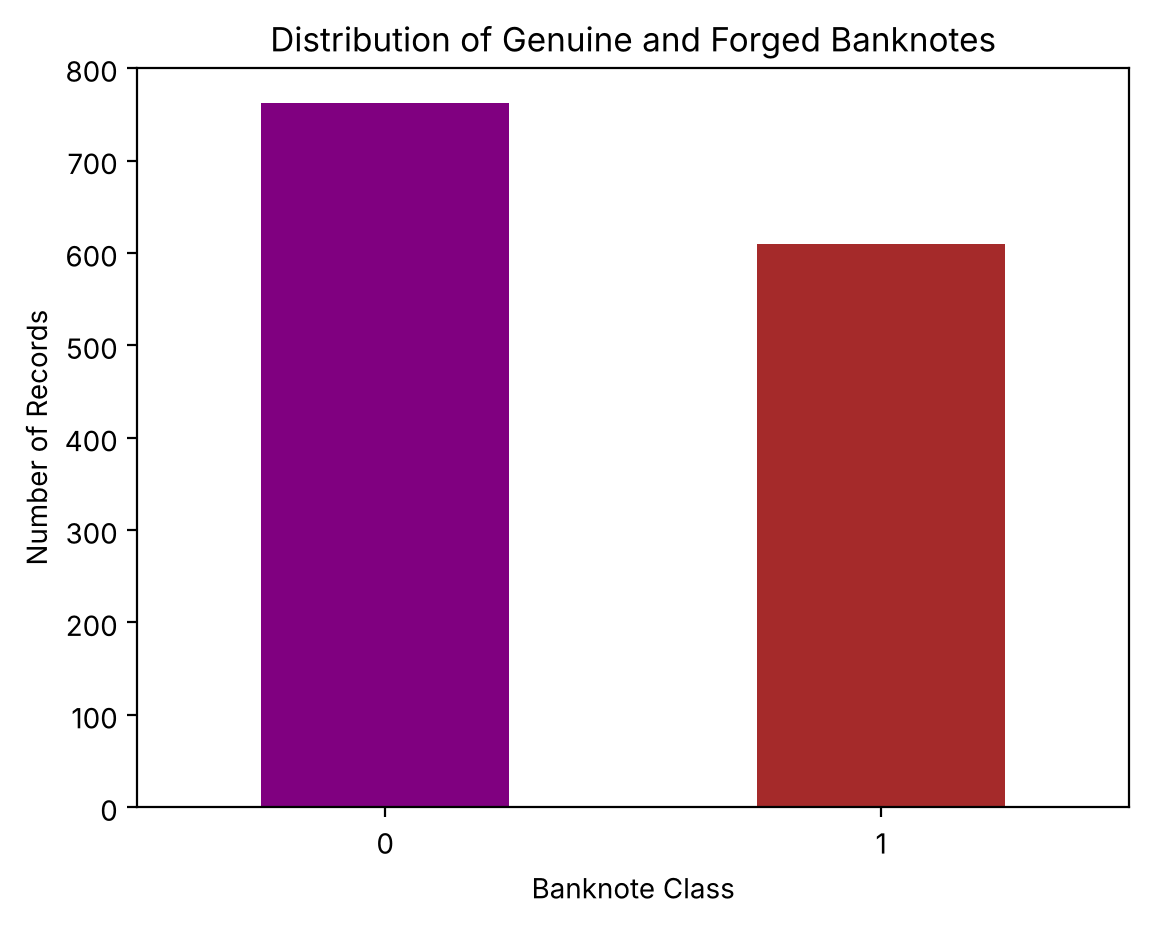

In [13]:

# Create a bar chart to show the number of banknotes in each class.
class_counts.plot(kind="bar", color=["purple", "brown"])

# Add a title to the graph.
plt.title("Distribution of Genuine and Forged Banknotes")

# Add a label to the horizontal axis.
plt.xlabel("Banknote Class")

# Add a label to the vertical axis.
plt.ylabel("Number of Records")

# Display the graph.
plt.xticks(rotation=0)
plt.show()


## Step 10: Remove duplicate records

**Why?** Earlier we found 24 repeated rows. If the same row lands in both the training set and the testing set, the model "sees the answer" before the exam. This is called **data leakage** and makes the score look better than it really is.

**Decision:** keep one copy of each repeated row and remove the extra copies.

In [14]:
# drop_duplicates() removes repeated rows. keep="first" keeps the first copy.
# reset_index(drop=True) renumbers the rows 0,1,2,... after removing rows.
df_clean = df.drop_duplicates(keep="first").reset_index(drop=True)

# Show how many rows we had before and after cleaning.
print("Rows before cleaning:", df.shape[0])
print("Rows after cleaning :", df_clean.shape[0])
print("Rows removed        :", df.shape[0] - df_clean.shape[0])

# Show the class counts again after cleaning.
print()
print(df_clean["class"].value_counts().sort_index())

Rows before cleaning: 1372
Rows after cleaning : 1348
Rows removed        : 24

class
0    738
1    610
Name: count, dtype: int64


**Note:** All the removed duplicate rows belonged to class 0 (genuine), so the genuine class became a little smaller. The dataset is still reasonably balanced.

In [15]:
# Import extra tools used in the next steps.
import os                                   # os helps us create folders.
from sklearn.pipeline import Pipeline       # Pipeline chains steps (scale -> model).
from sklearn.preprocessing import StandardScaler   # StandardScaler puts features on the same scale.
from sklearn.tree import DecisionTreeClassifier, plot_tree   # Decision Tree model and its drawing tool.
from sklearn.model_selection import StratifiedKFold, cross_validate   # Cross-validation tools.
from sklearn.metrics import ConfusionMatrixDisplay, make_scorer   # Draws a confusion matrix / builds a custom scorer.
from sklearn.inspection import permutation_importance   # Feature importance by shuffling.

# Create folders to save our graphs and result tables (does nothing if they already exist).
os.makedirs("images", exist_ok=True)
os.makedirs("reports", exist_ok=True)

# A fixed "random seed" so everyone who runs this notebook gets the same results.
RANDOM_STATE = 42

# The names of the four input columns.
feature_names = ["variance", "skewness", "curtosis", "entropy"]

print("Extra tools imported. Folders ready.")

Extra tools imported. Folders ready.


## Step 11: Exploratory Data Analysis (EDA)

EDA means **looking at the data with graphs before building models**. We want to see whether genuine and forged banknotes look different.

In [16]:
# Average value of each feature for genuine (0) and forged (1) banknotes.
print(df_clean.groupby("class")[feature_names].mean().round(3))

       variance  skewness  curtosis  entropy
class                                       
0         2.359     4.308     0.806   -1.104
1        -1.868    -0.994     2.148   -1.247


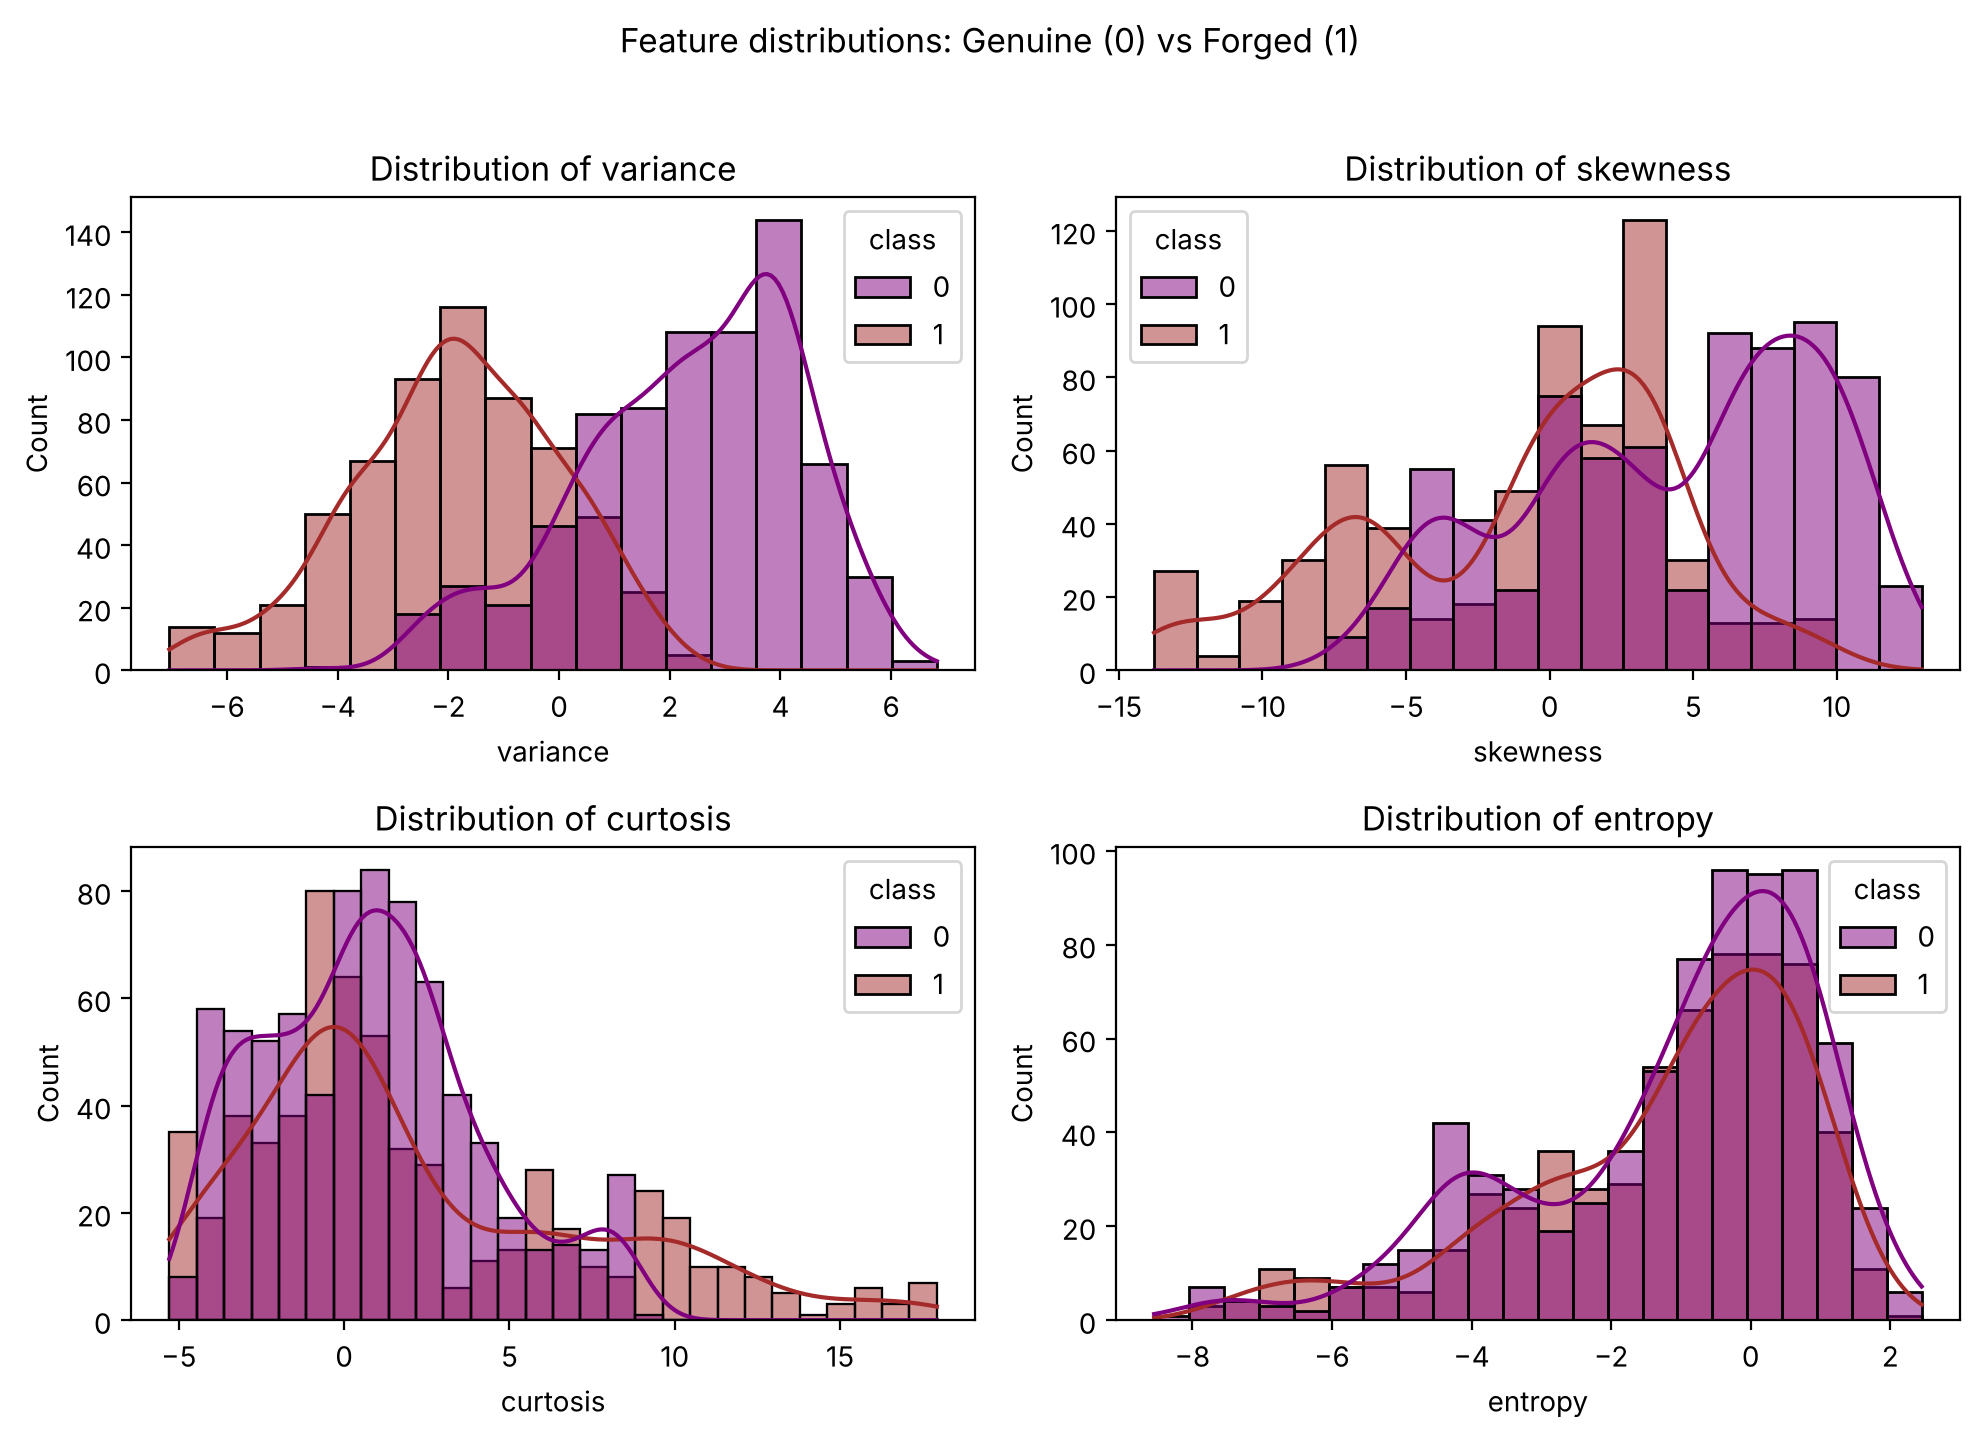

In [17]:
# Histograms: one small graph per feature, coloured by class.
fig, axes = plt.subplots(2, 2, figsize=(10, 7))   # 2 rows x 2 columns of graphs

for ax, feature in zip(axes.flatten(), feature_names):
    sns.histplot(data=df_clean, x=feature, hue="class", kde=True,
                 palette={0: "purple", 1: "brown"}, ax=ax)
    ax.set_title("Distribution of " + feature)

plt.suptitle("Feature distributions: Genuine (0) vs Forged (1)", y=1.02)
plt.tight_layout()
plt.savefig("images/feature_histograms.png", dpi=150, bbox_inches="tight")   # save the picture
plt.show()

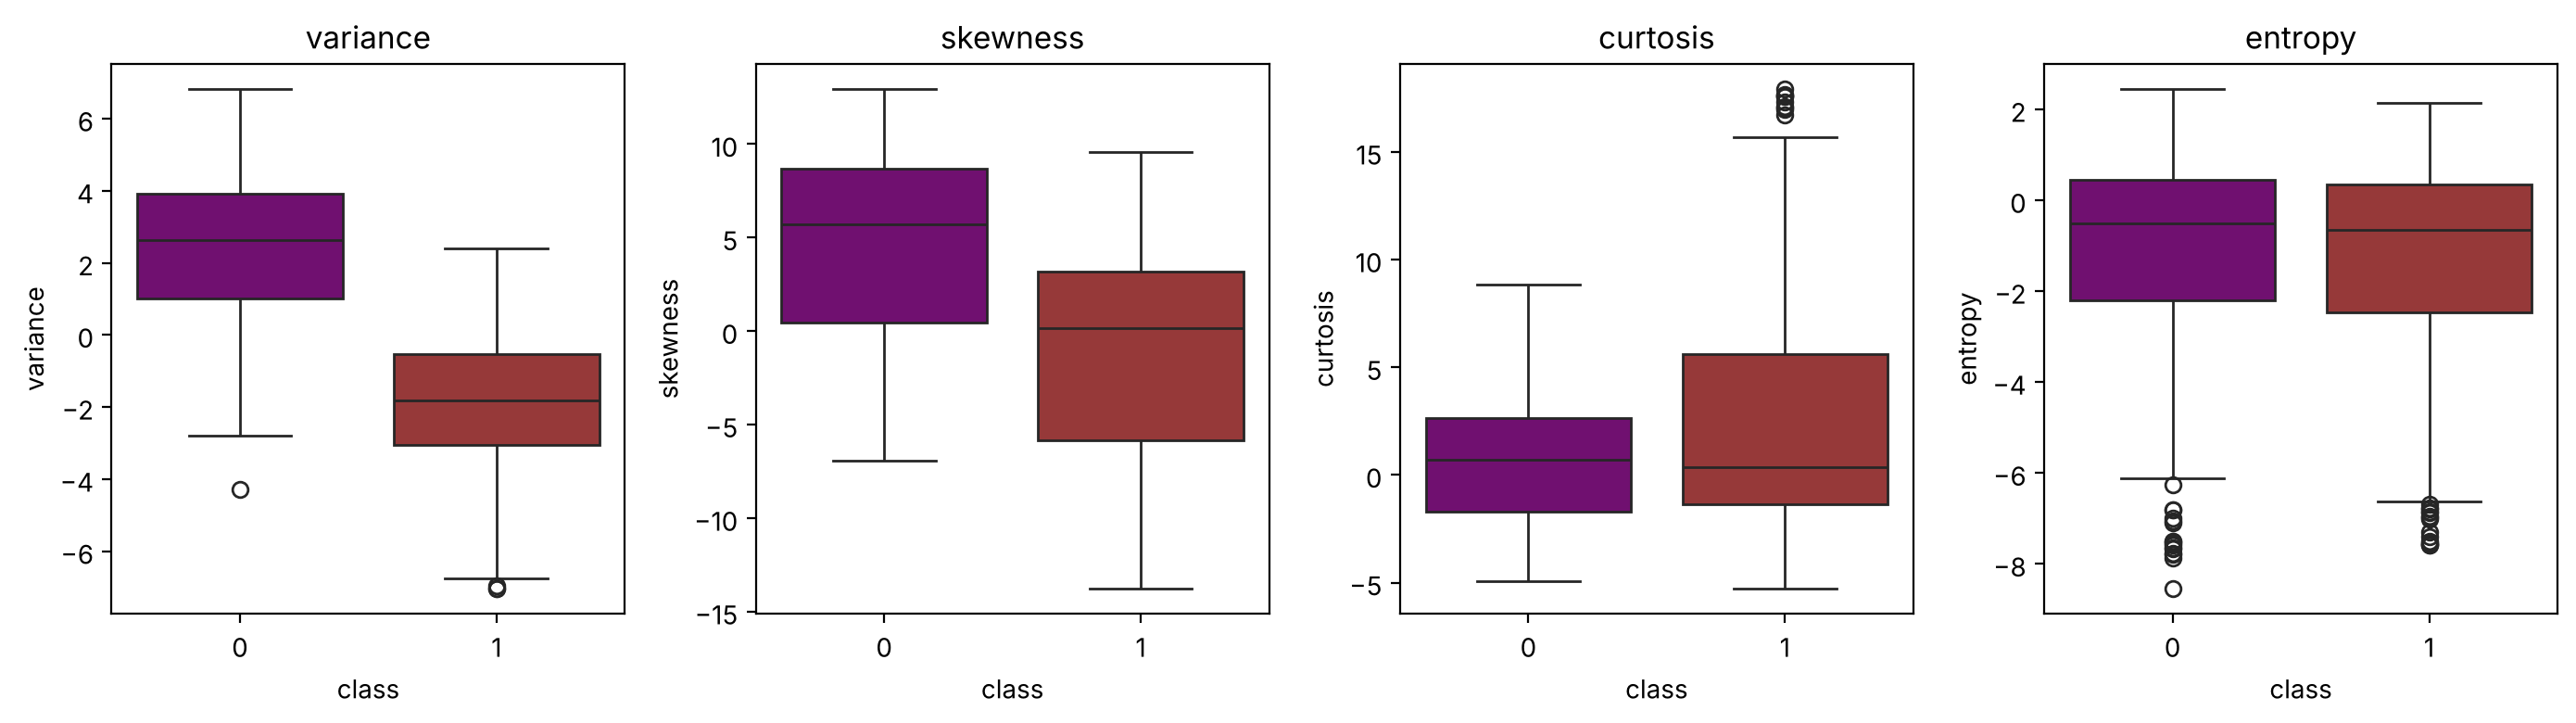

In [18]:
# Box plots: show the middle value and spread of each feature for each class.
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, feature in zip(axes, feature_names):
    sns.boxplot(data=df_clean, x="class", y=feature, hue="class",
                palette={0: "purple", 1: "brown"}, legend=False, ax=ax)
    ax.set_title(feature)

plt.tight_layout()
plt.savefig("images/feature_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

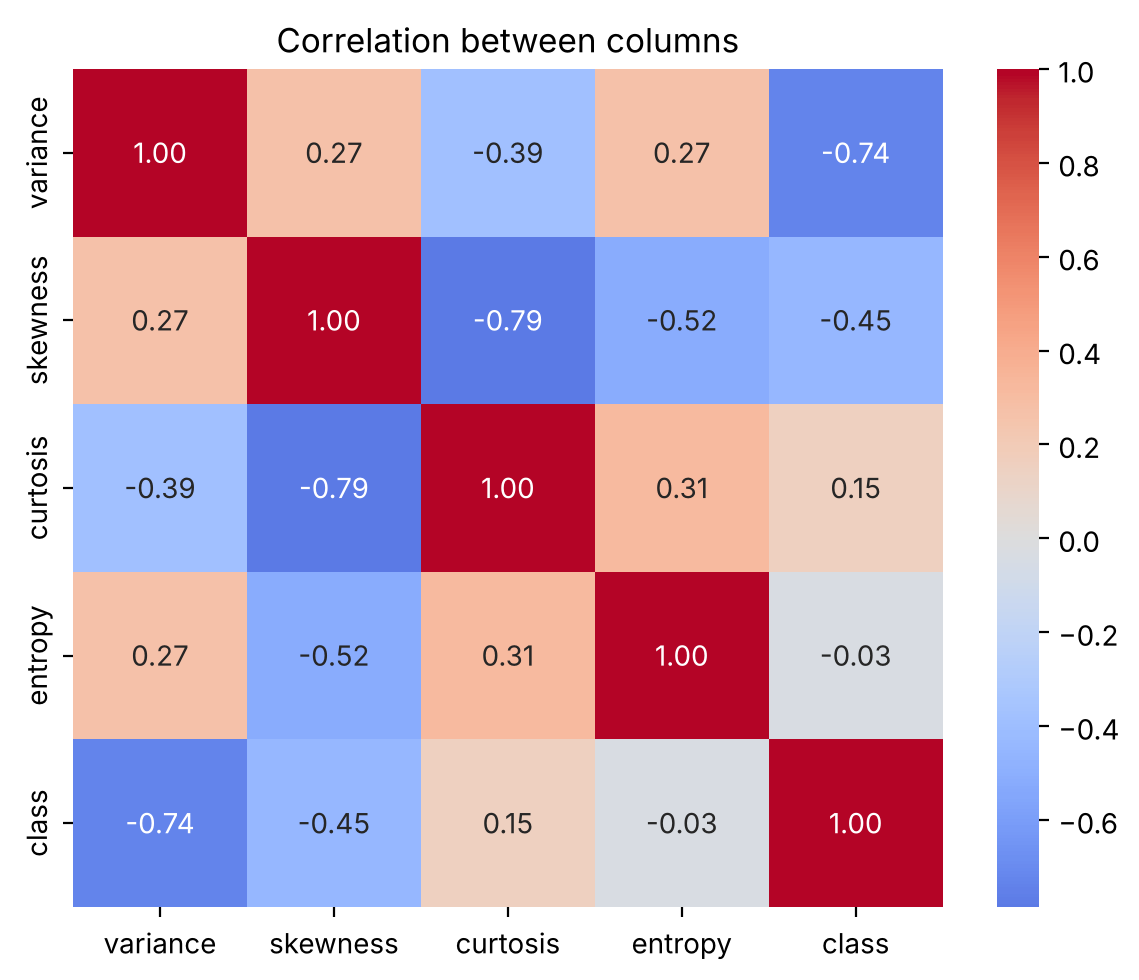

In [19]:
# Correlation heatmap: shows how strongly columns move together (-1 to +1).
plt.figure(figsize=(6, 5))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between columns")
plt.tight_layout()
plt.savefig("images/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see (EDA summary):** The graphs show that genuine and forged banknotes overlap, but they are clearly different in some features, especially **variance** and **skewness**. This tells us a machine learning model has a good chance of separating them. (See the printed averages and graphs above for the exact numbers.)

## Step 12: Separate inputs (X) and target (y)

- **X** = the four measurements (the question paper).
- **y** = the answer (0 genuine, 1 forged).

In [20]:
# X contains only the four input columns.
X = df_clean[feature_names]

# y contains only the answer column.
y = df_clean["class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1348, 4)
y shape: (1348,)


## Step 13: Split into training and testing sets

- **Training set (80%)**: the data the model learns from (like practice questions).
- **Testing set (20%)**: data the model has never seen (like the final exam).
- `stratify=y` keeps the same genuine/forged proportion in both sets.
- `random_state=42` makes the split the same every time.

In [21]:
# Split the data: 80% for training, 20% for testing.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,            # 20% of the rows go to the test set
    random_state=RANDOM_STATE, # fixed seed so results can be repeated
    stratify=y                 # keep class proportions equal in both sets
)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])
print()
print("Share of forged notes in training set:", round(y_train.mean(), 3))
print("Share of forged notes in testing set :", round(y_test.mean(), 3))

Training rows: 1078
Testing rows : 270

Share of forged notes in training set: 0.453
Share of forged notes in testing set : 0.452


**Preventing data leakage:** the scaler (see next steps) is placed *inside a Pipeline*, so it learns its averages **only from training data**. The test set stays completely unseen until the final evaluation.

## Step 14: Baseline model - Dummy Classifier

A Dummy Classifier does **not learn anything**. It always guesses the most common class. It is our "minimum score to beat". If a real model cannot beat the dummy, the model is useless.

In [22]:
# Create the dummy model. "most_frequent" means: always predict the most common class.
dummy_model = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)

# fit() = train the model using the training data.
dummy_model.fit(X_train, y_train)

print("Dummy Classifier trained.")

Dummy Classifier trained.


## Step 15: Logistic Regression with a preprocessing Pipeline

**Logistic Regression** is a simple model that calculates a probability (0 to 1) that a banknote is forged. If the probability is above 0.5, it predicts "forged".

**Scaling:** the four features have different sizes (skewness ranges about -14 to 13, entropy about -8 to 2). `StandardScaler` converts every feature to a similar scale so the model treats them fairly.

**Pipeline:** chains "scale, then model" together so scaling is learned from training data only.

In [23]:
# Build the pipeline: step 1 = scale the data, step 2 = Logistic Regression.
log_reg_model = Pipeline(steps=[
    ("scaler", StandardScaler()),                                    # step 1
    ("classifier", LogisticRegression(max_iter=1000,                 # step 2
                                      random_state=RANDOM_STATE))
])

# Train the whole pipeline on training data only.
log_reg_model.fit(X_train, y_train)

print("Logistic Regression trained.")

Logistic Regression trained.


## Step 16: Decision Tree

A **Decision Tree** asks a series of yes/no questions, like "Is variance less than 0.3?", until it reaches an answer. It needs no scaling.

**Overfitting warning:** a tree with no limits can memorise the training data. We limit it to `max_depth=4` (at most 4 questions in a row). We also train an unlimited tree below, only to *demonstrate* overfitting.

In [24]:
# The main tree: limited to 4 levels of questions.
tree_model = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
tree_model.fit(X_train, y_train)

# A demonstration tree with NO depth limit (only used to show overfitting).
deep_tree_demo = DecisionTreeClassifier(random_state=RANDOM_STATE)
deep_tree_demo.fit(X_train, y_train)

print("Decision Tree trained.")
print("Depth of the unlimited demo tree:", deep_tree_demo.get_depth())

Decision Tree trained.
Depth of the unlimited demo tree: 7


## Step 17-18: Compare the models (accuracy, precision, recall, F1-score)

We measure every model on the **test set** (data it has never seen). **Forged = 1 is our "positive" class.**

| Metric | Simple meaning |
|---|---|
| Accuracy | Out of all banknotes, how many were predicted correctly? |
| Precision | Out of notes predicted *forged*, how many really were forged? |
| Recall | Out of all *really forged* notes, how many did we catch? |
| F1-score | One number that balances precision and recall. |

In [25]:
# Put all models in one dictionary so we can loop through them.
models = {
    "Dummy Classifier": dummy_model,
    "Logistic Regression": log_reg_model,
    "Decision Tree (depth 4)": tree_model,
}

rows = []   # an empty list to collect results

for name, model in models.items():
    y_pred = model.predict(X_test)   # predict the answers for the test set
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall":    recall_score(y_test, y_pred),
        "F1-score":  f1_score(y_test, y_pred),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results.to_csv("reports/model_results.csv")   # save the table
results

,Accuracy,Precision,Recall,F1-score
Model,,,,
Dummy Classifier,0.5481,0.0000,0.0,0.0000
Logistic Regression,0.9852,0.9683,1.0,0.9839
Decision Tree (depth 4),0.9778,0.9531,1.0,0.9760


In [26]:
# Overfitting check: compare accuracy on training data vs testing data.
for name, model in [("Logistic Regression", log_reg_model),
                    ("Decision Tree (depth 4)", tree_model),
                    ("Unlimited tree (demo only)", deep_tree_demo)]:
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    print(f"{name:28s} train accuracy = {train_acc:.4f}   test accuracy = {test_acc:.4f}")

Logistic Regression          train accuracy = 0.9944   test accuracy = 0.9852
Decision Tree (depth 4)      train accuracy = 0.9768   test accuracy = 0.9778
Unlimited tree (demo only)   train accuracy = 1.0000   test accuracy = 0.9963


## Step 19: Confusion matrices

A confusion matrix is a small table that counts correct and wrong predictions:

| | Predicted Genuine | Predicted Forged |
|---|---|---|
| **Actually Genuine** | True Negative (correct) | **False Positive** (genuine note wrongly called forged) |
| **Actually Forged** | **False Negative** (forged note wrongly accepted!) | True Positive (correct) |

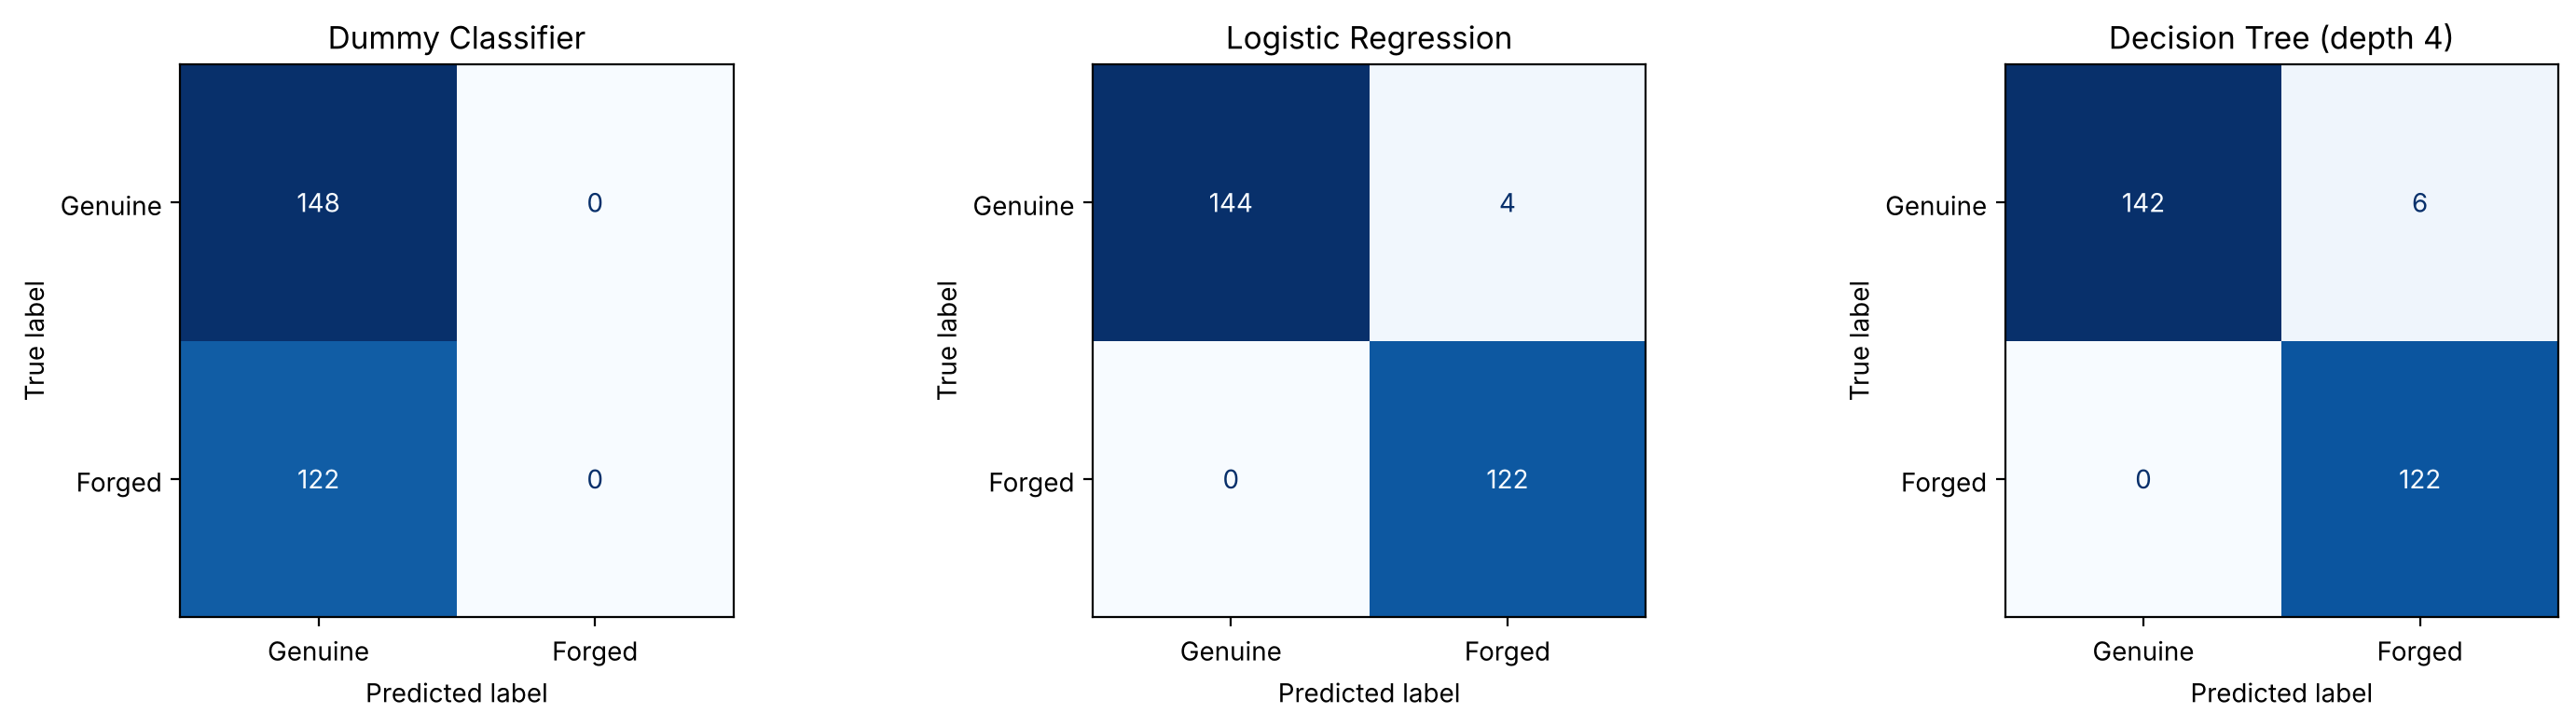

In [27]:
# Draw one confusion matrix for each model.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        display_labels=["Genuine", "Forged"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.savefig("images/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
# Print the confusion-matrix numbers in words.
for name, model in models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, model.predict(X_test)).ravel()
    print(f"{name}")
    print(f"   Genuine correctly accepted (TN): {tn}")
    print(f"   Genuine wrongly called forged (FP): {fp}")
    print(f"   Forged wrongly accepted as genuine (FN): {fn}")
    print(f"   Forged correctly caught (TP): {tp}")
    print()

# Full report for Logistic Regression.
print(classification_report(y_test, log_reg_model.predict(X_test),
                            target_names=["Genuine (0)", "Forged (1)"]))

Dummy Classifier
   Genuine correctly accepted (TN): 148
   Genuine wrongly called forged (FP): 0
   Forged wrongly accepted as genuine (FN): 122
   Forged correctly caught (TP): 0

Logistic Regression
   Genuine correctly accepted (TN): 144
   Genuine wrongly called forged (FP): 4
   Forged wrongly accepted as genuine (FN): 0
   Forged correctly caught (TP): 122

Decision Tree (depth 4)
   Genuine correctly accepted (TN): 142
   Genuine wrongly called forged (FP): 6
   Forged wrongly accepted as genuine (FN): 0
   Forged correctly caught (TP): 122

              precision    recall  f1-score   support

 Genuine (0)       1.00      0.97      0.99       148
  Forged (1)       0.97      1.00      0.98       122

    accuracy                           0.99       270
   macro avg       0.98      0.99      0.99       270
weighted avg       0.99      0.99      0.99       270



## Step 20: Cross-validation (training data only)

A single train/test split can be lucky or unlucky. **5-fold cross-validation** splits the *training data* into 5 parts. The model trains on 4 parts and is checked on the remaining part, 5 times. We then look at the average and the spread.

The test set is **not touched** here. Because the scaler is inside the pipeline, it is re-learned inside each fold (no leakage).

In [29]:
# 5 folds, shuffled, keeping class proportions equal in every fold.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=skf,
        scoring={"accuracy": "accuracy",
                 "precision": make_scorer(precision_score, zero_division=0),  # avoids warning for the dummy model
                 "recall": "recall",
                 "f1": "f1"}
    )
    cv_rows.append({
        "Model": name,
        "CV Accuracy (mean)":  scores["test_accuracy"].mean(),
        "CV Accuracy (std)":   scores["test_accuracy"].std(),
        "CV Precision (mean)": scores["test_precision"].mean(),
        "CV Recall (mean)":    scores["test_recall"].mean(),
        "CV F1 (mean)":        scores["test_f1"].mean(),
    })

cv_results = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_results.to_csv("reports/cross_validation_results.csv")
cv_results

,CV Accuracy (mean),CV Accuracy (std),CV Precision (mean),CV Recall (mean),CV F1 (mean)
Model,,,,,
Dummy Classifier,0.5473,0.0012,0.0000,0.0000,0.0000
Logistic Regression,0.9944,0.0019,0.9899,0.9980,0.9939
Decision Tree (depth 4),0.9545,0.0115,0.9366,0.9652,0.9504


## Step 21: Error analysis - investigate the wrong predictions

Good data scientists do not stop at accuracy. We look at **exactly which banknotes were predicted wrongly** and try to understand why.

In [30]:
# Find every wrong prediction made by each model on the test set.
error_tables = {}

for name in ["Logistic Regression", "Decision Tree (depth 4)"]:
    model = models[name]
    table = X_test.copy()                          # start with the feature values
    table["true_class"] = y_test                   # the real answer
    table["predicted_class"] = model.predict(X_test)   # the model's answer
    if name == "Logistic Regression":
        # Probability of being forged (shows how confident the model was).
        table["forged_probability"] = model.predict_proba(X_test)[:, 1].round(3)
    wrong = table[table["true_class"] != table["predicted_class"]].copy()
    wrong["error_type"] = wrong["true_class"].map({0: "False Positive (genuine called forged)",
                                                   1: "False Negative (forged called genuine)"})
    error_tables[name] = wrong
    print(f"{name}: {len(wrong)} wrong predictions out of {len(X_test)} test notes")

Logistic Regression: 4 wrong predictions out of 270 test notes
Decision Tree (depth 4): 6 wrong predictions out of 270 test notes


In [31]:
# Show the wrong predictions of Logistic Regression.
error_tables["Logistic Regression"]

,variance,skewness,curtosis,entropy,true_class,predicted_class,forged_probability,error_type
243,0.37980,0.7098,0.7572,-0.4444,0,1,0.688,False Positive (genuine called forged)
21,0.32920,-4.4552,4.5718,-0.9888,0,1,0.760,False Positive (genuine called forged)
106,-1.85840,7.8860,-1.6643,-1.8384,0,1,0.716,False Positive (genuine called forged)
4,0.32924,-4.4552,4.5718,-0.9888,0,1,0.760,False Positive (genuine called forged)


In [32]:
# Show the wrong predictions of the Decision Tree.
error_tables["Decision Tree (depth 4)"]

,variance,skewness,curtosis,entropy,true_class,predicted_class,error_type
243,0.37980,0.70980,0.7572,-0.444400,0,1,False Positive (genuine called forged)
34,-1.61620,0.80908,8.1628,0.608170,0,1,False Positive (genuine called forged)
85,-1.13130,1.90370,7.5339,1.022000,0,1,False Positive (genuine called forged)
170,-1.69520,1.06570,8.8294,0.949550,0,1,False Positive (genuine called forged)
629,-0.38388,-1.04710,8.0514,0.495670,0,1,False Positive (genuine called forged)
461,-1.77810,0.85460,7.1303,0.027572,0,1,False Positive (genuine called forged)


In [33]:
# Honest note about the number of errors (we never invent errors).
total_errors = sum(len(t) for t in error_tables.values())
for name, t in error_tables.items():
    if len(t) < 10:
        print(f"{name} made fewer than 10 errors ({len(t)}), so we study all of them. We do not invent extra errors.")

# Save all errors to a file for the report.
pd.concat(error_tables, names=["model"]).to_csv("reports/misclassified_test_records.csv")

# Which test notes were wrong for BOTH models? These are the 'hardest' notes.
both = error_tables["Logistic Regression"].index.intersection(error_tables["Decision Tree (depth 4)"].index)
print("Notes wrong for BOTH models (row numbers):", list(both))

# For comparison: the average feature values of each true class in the training data.
print()
print("Average training values per class (for comparison):")
print(pd.concat([X_train, y_train], axis=1).groupby("class")[feature_names].mean().round(3))

Logistic Regression made fewer than 10 errors (4), so we study all of them. We do not invent extra errors.
Decision Tree (depth 4) made fewer than 10 errors (6), so we study all of them. We do not invent extra errors.
Notes wrong for BOTH models (row numbers): [243]

Average training values per class (for comparison):
       variance  skewness  curtosis  entropy
class                                       
0         2.411     4.310     0.721   -1.087
1        -1.791    -1.047     2.118   -1.235


## Step 22: Feature importance - which features matter most?

We use three simple methods:
1. **Logistic Regression coefficients** (on scaled data): bigger absolute number = stronger influence. Positive pushes toward "forged".
2. **Decision Tree importance**: how much each feature helped the tree's questions.
3. **Permutation importance**: shuffle one feature in the test set; if accuracy drops a lot, that feature was important.

          LogReg coefficient  Tree importance  \
variance             -4.6347           0.7031   
skewness             -4.7386           0.1547   
curtosis             -4.3971           0.1422   
entropy               0.2355           0.0000   

          Permutation importance (accuracy drop)  
variance                                  0.3998  
skewness                                  0.3025  
curtosis                                  0.1695  
entropy                                   0.0000  


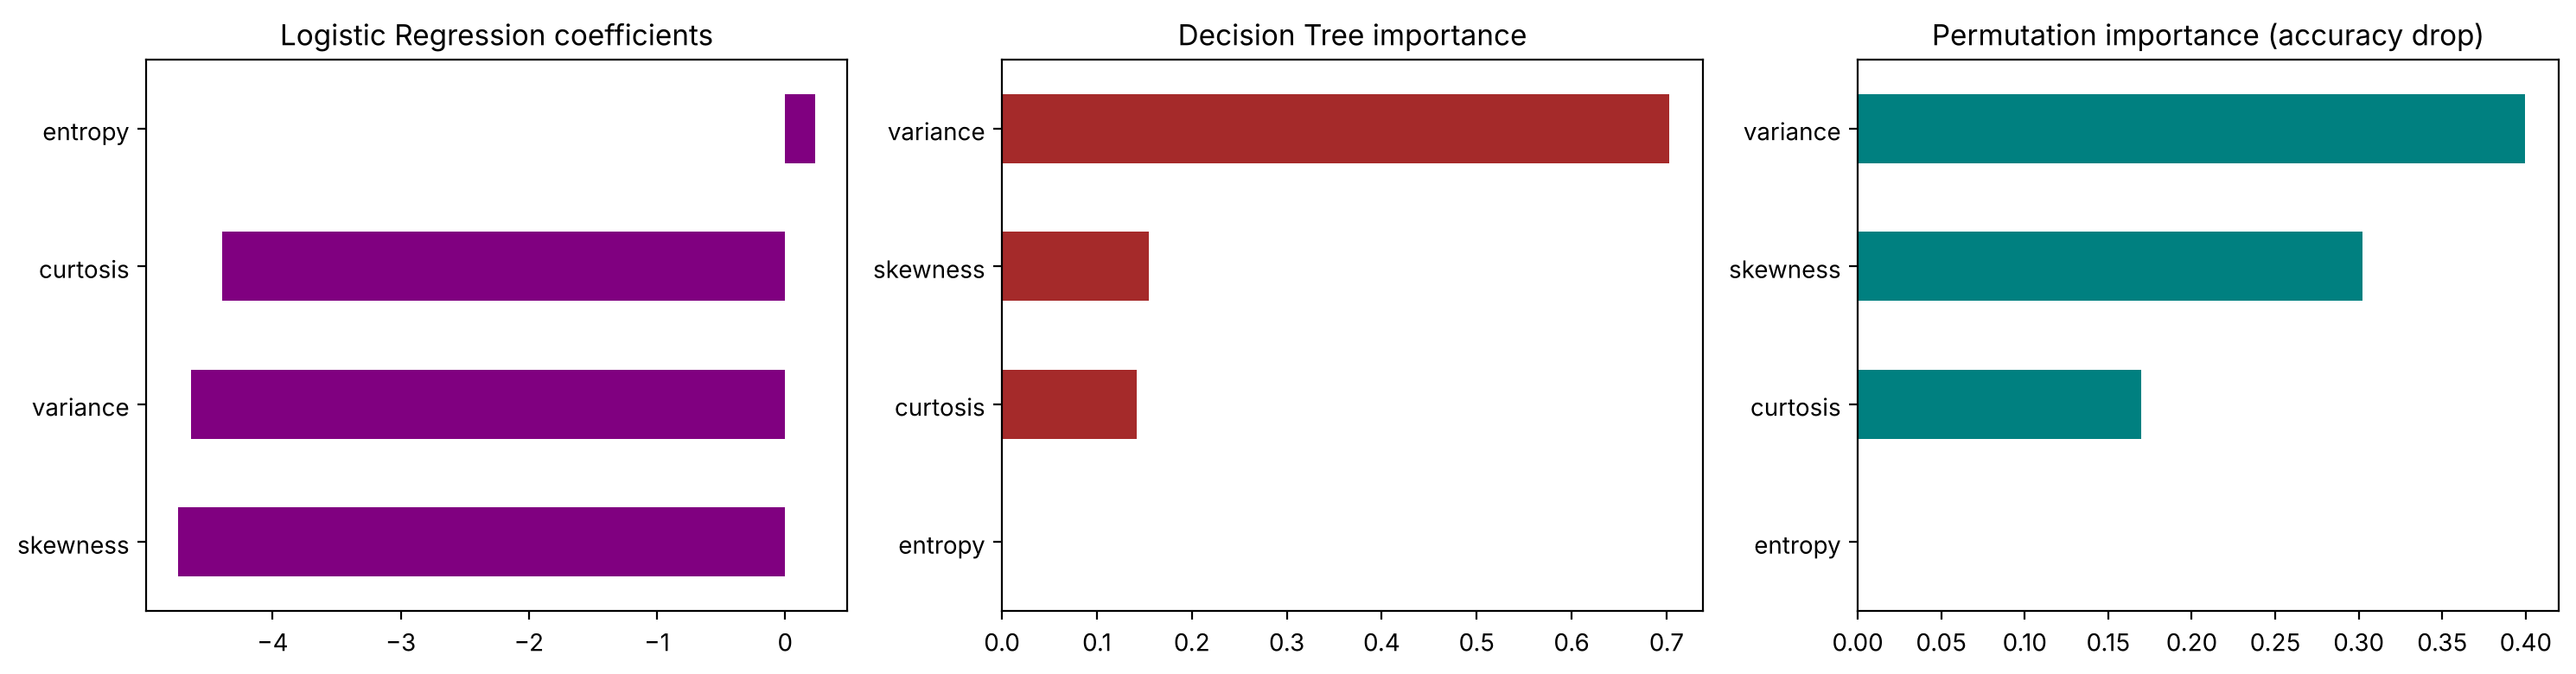

In [34]:
# 1) Logistic Regression coefficients (these belong to the scaled features).
lr_coefs = pd.Series(log_reg_model.named_steps["classifier"].coef_[0], index=feature_names)

# 2) Decision Tree feature importances (they add up to 1).
tree_imp = pd.Series(tree_model.feature_importances_, index=feature_names)

# 3) Permutation importance on the test set for Logistic Regression.
perm = permutation_importance(log_reg_model, X_test, y_test, scoring="accuracy",
                              n_repeats=30, random_state=RANDOM_STATE)
perm_imp = pd.Series(perm.importances_mean, index=feature_names)

importance_table = pd.DataFrame({
    "LogReg coefficient": lr_coefs,
    "Tree importance": tree_imp,
    "Permutation importance (accuracy drop)": perm_imp,
}).round(4)
importance_table.to_csv("reports/feature_importance.csv")
print(importance_table)

# Draw the three importance charts side by side.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
lr_coefs.sort_values().plot(kind="barh", ax=axes[0], color="purple")
axes[0].set_title("Logistic Regression coefficients")
tree_imp.sort_values().plot(kind="barh", ax=axes[1], color="brown")
axes[1].set_title("Decision Tree importance")
perm_imp.sort_values().plot(kind="barh", ax=axes[2], color="teal")
axes[2].set_title("Permutation importance (accuracy drop)")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

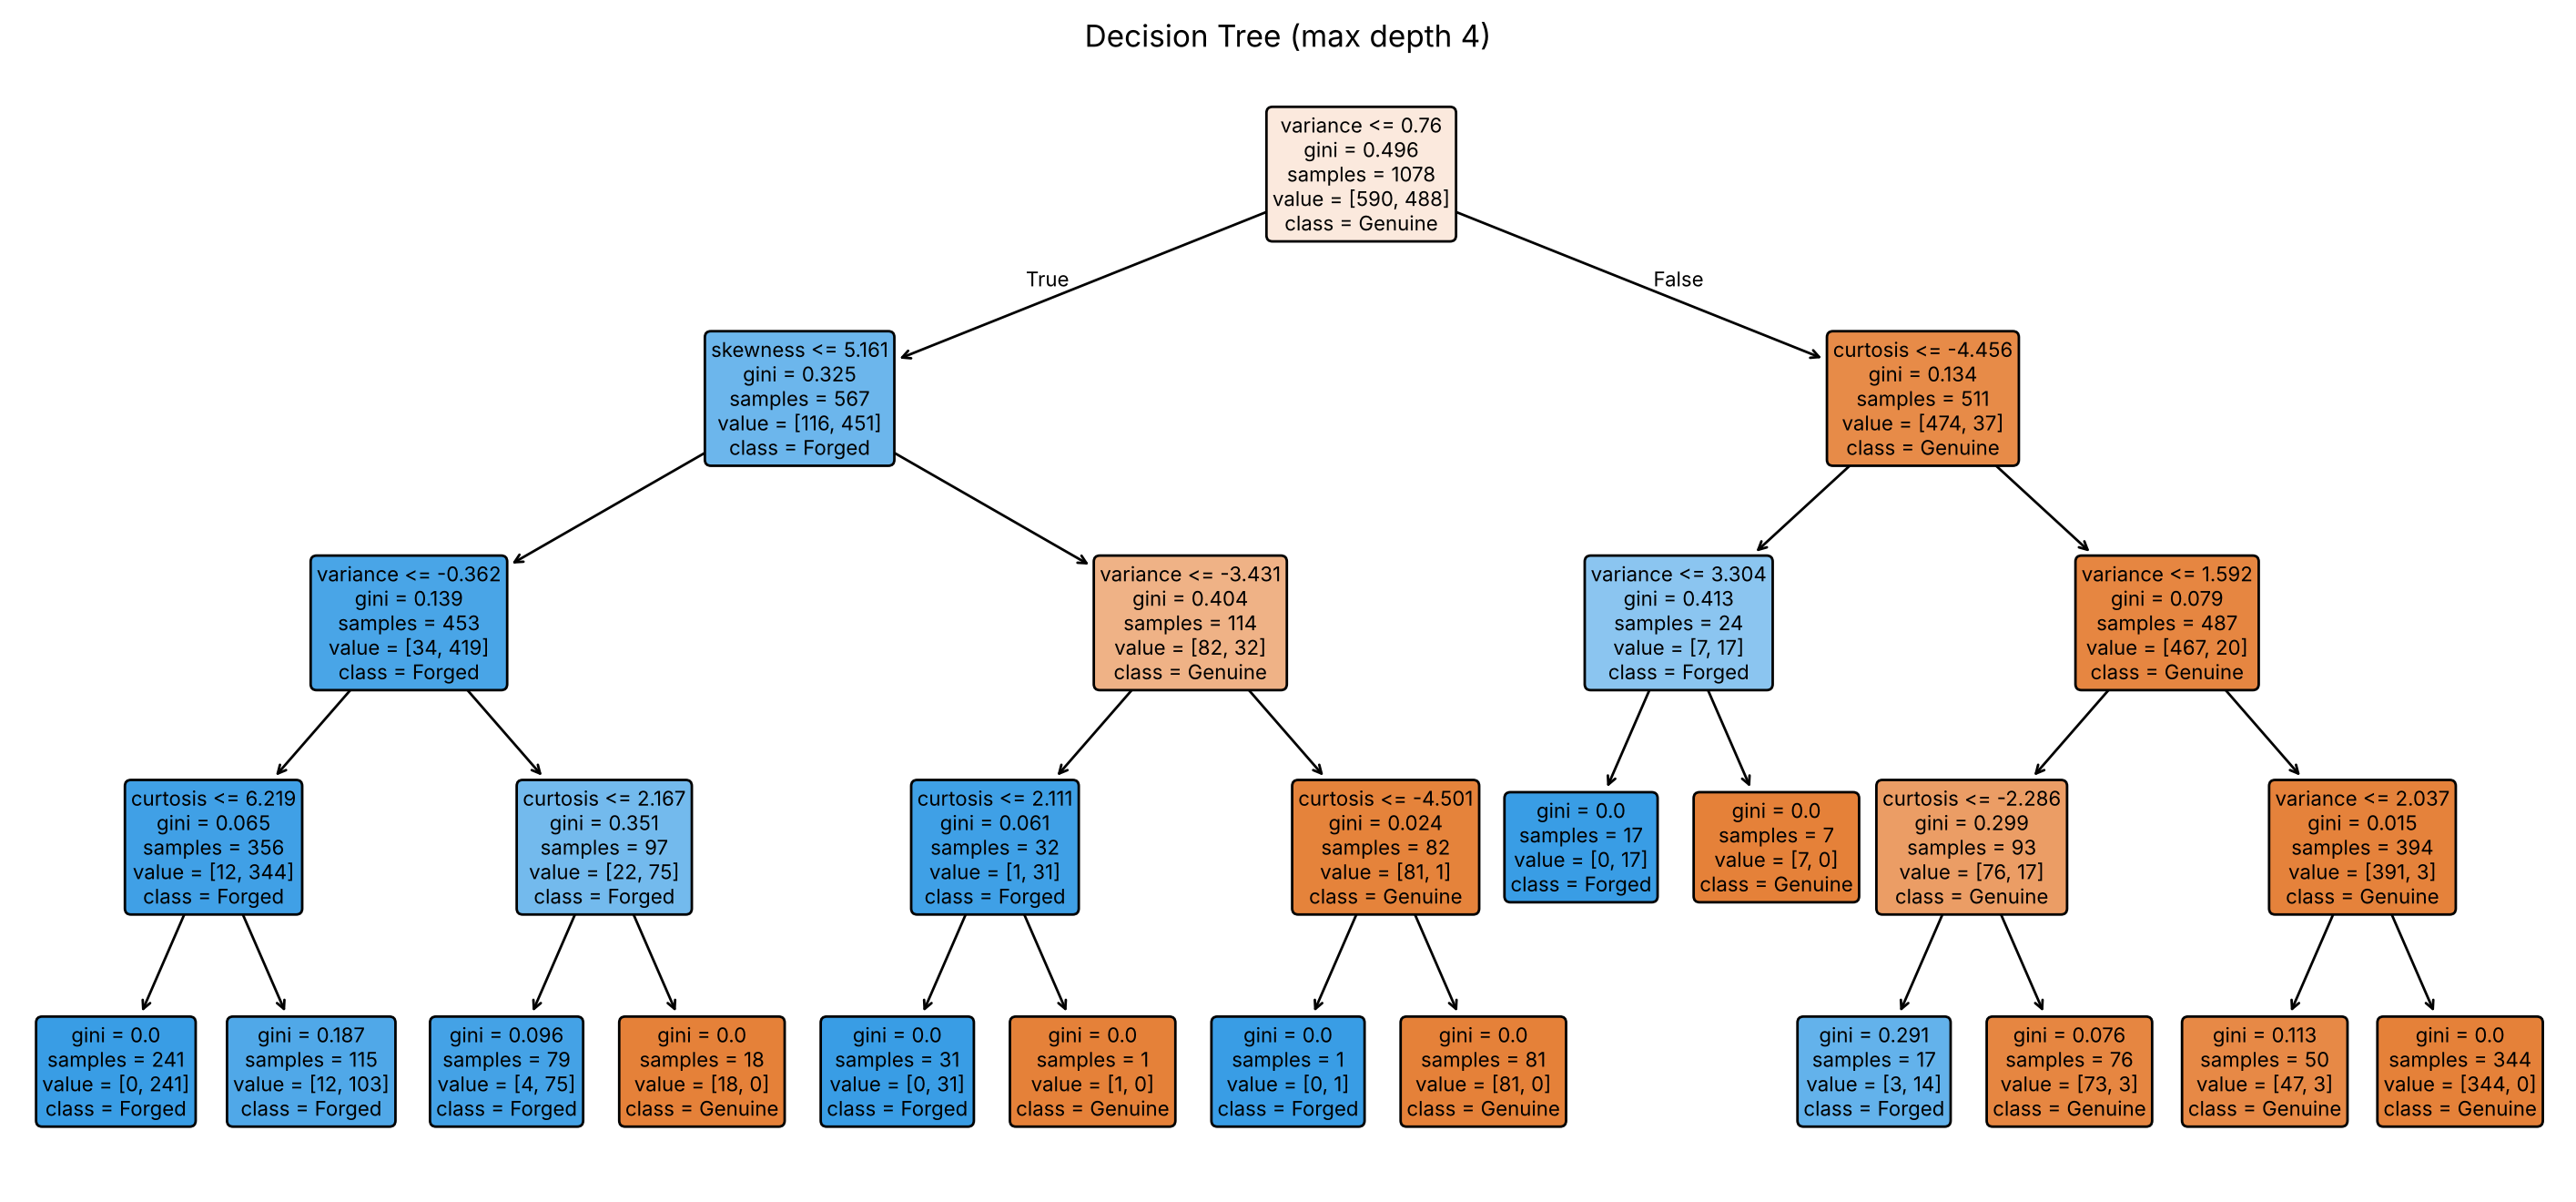

In [35]:
# Draw the Decision Tree so we can read its questions.
plt.figure(figsize=(18, 8))
plot_tree(tree_model, feature_names=feature_names,
          class_names=["Genuine", "Forged"], filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree (max depth 4)")
plt.savefig("images/decision_tree.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 23: What do the results tell us?

*(Numbers below come from the executed cells above, with random seed 42.)*

- **Baseline:** the Dummy Classifier got about **54.8%** accuracy, because it always says "genuine" and ~55% of test notes are genuine. It caught **0** forged notes (recall 0). This is the score to beat.
- **Logistic Regression:** **98.5%** test accuracy (4 mistakes out of 270), precision 0.968, recall 1.000, F1 0.984.
- **Decision Tree (depth 4):** **97.8%** test accuracy (6 mistakes out of 270), precision 0.953, recall 1.000, F1 0.976.
- **Cross-validation (training data only):** Logistic Regression averaged **99.4%** accuracy with a very small spread (std 0.002). The depth-4 Decision Tree averaged **95.5%** with a larger spread (std 0.012). So Logistic Regression is both better and more stable.
- **Overfitting check:** train and test accuracy are close for Logistic Regression (99.4% vs 98.5%) and the depth-4 tree (97.7% vs 97.8%), so there is no clear sign of overfitting. The unlimited tree reached 100% train accuracy and 99.6% test accuracy on this particular split, so on this dataset we did **not** see it overfit badly. We still keep the depth-4 tree for simplicity and easy explanation, and we note that it scored lower in cross-validation (this shows one test split can be lucky).
- **Confusion matrices:** both models caught every forged note in the test set (0 false negatives). All their mistakes were **false positives**: genuine notes wrongly called forged (4 for Logistic Regression, 6 for the tree).

### Error analysis findings
- Only **4** (Logistic Regression) and **6** (Decision Tree) mistakes exist, fewer than ten each. We studied all of them and did not invent more.
- Only one test note (row 243) was wrong for **both** models. Its feature values (variance 0.38, skewness 0.71, curtosis 0.76, entropy -0.44) lie close to the middle of the data, between the typical genuine and forged values.
- The Logistic Regression mistakes had forged probabilities of only about 0.69 to 0.76, so the model was **not very confident** on them. Low confidence is a useful warning sign.
- Two of the four Logistic Regression errors (rows 21 and 4) have almost identical feature values. They are the same banknote record stored with different rounding (0.3292 vs 0.32924), so they are really one hard case counted twice. Our exact-duplicate check could not detect this.
- The tree's mistakes mostly have high curtosis (about 7 to 9) and low variance, a region where the depth-4 tree's rules were not precise enough.

### Feature importance findings
- Logistic Regression and permutation importance both rank **variance, skewness and curtosis** as the useful features, with **variance** and **skewness** most important. **Entropy** has almost no effect (coefficient 0.24, tree importance 0, permutation importance 0).
- The Decision Tree relies most on **variance** (importance about 0.70).
- Important: feature importance explains the *model*, not the real banknote. It does not prove that variance *causes* a note to be forged.

## Step 24: Limitations and Responsible AI risks

**Limitations**
1. **Small and old dataset:** only 1,348 records after cleaning, from a research collection of banknote images. It does not represent all banknotes, currencies, printers, scanners or fake-making methods.
2. **Features are pre-calculated:** the four numbers come from a Wavelet Transform of scanned images. The model never sees a real banknote, and scans from other cameras or lighting may give different numbers.
3. **Very high scores can mislead:** the dataset is "easy". Real forgers adapt, so real-world performance would likely be lower.
4. **Small test set:** 270 test notes (122 forged). One extra mistake changes accuracy by about 0.4 percentage points.
5. **Near-duplicates:** after removing 24 exact duplicates, a few rows (about 5) that differ only by rounding remain. At most one test note has a near-copy in the training data, so leakage is very small but not exactly zero.
6. **Currency unknown:** the dataset does not say which country or currency the notes belong to.
7. **No demographic data:** the dataset has no information about people, so **demographic fairness cannot be assessed**.

**Risks**
- **False positive** (genuine called forged): an honest person or shop could be wrongly accused or lose money. All of our test errors were of this type.
- **False negative** (forged called genuine): a fake note is accepted and someone loses money. We had 0 in the test set, but with a small test set this does not guarantee it will never happen.
- **Over-trust (automation bias):** people may believe the computer and stop checking carefully.
- **Misuse:** using this educational model as a real banknote checker.

**Responsible use:** This is an **educational model only**. It is **not a certified banknote authentication system** and must **not be the only basis for any financial or legal decision**. A human expert should review uncertain cases.

## Step 25: Final conclusion

We trained and compared three models on the UCI Banknote Authentication dataset after removing 24 duplicate rows, using a stratified 80/20 split, a scaling pipeline fitted only on training data, and 5-fold cross-validation on training data only.

- The simple **Logistic Regression** model performed best: **98.5% test accuracy**, 100% recall for forged notes and a stable cross-validation accuracy of **99.4%**. It beat the Dummy baseline (54.8%) by a large margin.
- The **Decision Tree** was slightly weaker but easier to explain.
- All test mistakes were genuine notes wrongly called forged, and the model was less confident on them.
- **Variance** and **skewness** were the most useful features; **entropy** was almost useless.

High accuracy on a small, clean research dataset does **not** mean the model is safe for real-world use. The accompanying Model Card (`reports/model_card.md`) documents the data, metrics, limitations, risks and responsible use.